# Ordinal-model cluster error analysis

Post-processing of the locked `M1_I1_final` **ordinal model** using out-of-fold predictions and each fold's fitted ordinal cut points. Predictions are joined to the existing physicochemical amendment, pesticide, and soil clusters. Repeated predictions from five seeds are retained for rates, while `n_observations` and `n_studies` show independent support.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Circle, FancyBboxPatch, Patch
plt.rcParams.update({'font.family': 'Arial', 'font.size': 12})

RUN = Path('outputs/20260916_122112_M1_I1_final')
OUT = RUN / 'ordinal_cluster_error_postprocessing'
OUT.mkdir(exist_ok=True)

OA = 'amendment_cluster_chemical'
PEST = 'pesticide_rdkit_cluster'
SOIL = 'soil_cluster'
MIN_N = 10

frame = pd.read_pickle('model_df.pkl')
oof = pd.read_csv(RUN / 'oof_ordinal_with_cuts.csv')
continuous_candidates = ['soil_silt', 'soil_pH', 'soil_OC', 'amendment_pH', 'amendment_carbon',
                         'amendment_application_rate_g_kg', 'log1p_pesticide_concentration',
                         'pesticide_logD_at_soil_pH', 'biowin4_primary', 'ln_DT50_ratio']
CONTINUOUS = [c for c in continuous_candidates if c in frame]
print('Continuous profiles:', CONTINUOUS)
print('Unavailable in model_df:', sorted(set(continuous_candidates) - set(CONTINUOUS)))
ids = ['analysis_row_id', 'Study ID', 'Amendment ID', 'Pesticide ID', 'Pesticide name', 'Soil ID']
meta = frame[ids + [OA, PEST, SOIL, 'feedstock_group', 'processing_group'] + CONTINUOUS].drop_duplicates('analysis_row_id')
data = oof.merge(meta, on=['analysis_row_id', 'Study ID'], how='left', validate='many_to_one')
print('Missing cluster assignments:', data[[OA, PEST, SOIL]].isna().mean().round(3).to_dict())

order = {'faster': 0, 'no change': 1, 'slower': 2}
data['error_step'] = data['predicted'].map(order) - data['observed'].map(order)
data['error_type'] = np.select(
    [data['error_step'].eq(0), data['error_step'].abs().eq(2), data['error_step'].gt(0)],
    ['correct', 'reversal', 'toward slower'], default='toward faster')
data['transition'] = data['observed'] + ' → ' + data['predicted']
data['boundary_distance'] = data['distance_to_nearest_cut']
HIGH_MARGIN = data['boundary_distance'].quantile(.75)
print(f'{len(meta):,} observations, {data["Study ID"].nunique()} studies, {len(data):,} OOF predictions')


Continuous profiles: ['soil_silt', 'soil_pH', 'soil_OC', 'amendment_pH', 'amendment_carbon', 'amendment_application_rate_g_kg', 'log1p_pesticide_concentration', 'ln_DT50_ratio']
Unavailable in model_df: ['biowin4_primary', 'pesticide_logD_at_soil_pH']
Missing cluster assignments: {'amendment_cluster_chemical': 0.26, 'pesticide_rdkit_cluster': 0.0, 'soil_cluster': 0.249}
450 observations, 67 studies, 2,250 OOF predictions


In [2]:
def summarize(group_cols):
    source = data.dropna(subset=group_cols)
    g = source.groupby(group_cols, dropna=False)
    out = g.agg(
        n_predictions=('correct', 'size'),
        n_observations=('analysis_row_id', 'nunique'),
        n_studies=('Study ID', 'nunique'),
        accuracy=('correct', 'mean'),
        reversal_rate=('directional_reversal', 'mean'),
        mean_abs_error=('error_step', lambda x: x.abs().mean()),
    ).reset_index()
    wrong = source.loc[~source['correct']].groupby(group_cols)['transition'].agg(lambda x: x.value_counts().index[0]).rename('dominant_error')
    out = out.merge(wrong, on=group_cols, how='left')
    out['error_rate'] = 1 - out['accuracy']
    return out.sort_values(['error_rate', 'n_observations'], ascending=[False, False])

tables = {
    'amendment': summarize([OA]),
    'pesticide': summarize([PEST]),
    'soil': summarize([SOIL]),
    'pesticide_x_amendment': summarize([PEST, OA]),
    'soil_x_amendment': summarize([SOIL, OA]),
    'pesticide_x_soil': summarize([PEST, SOIL]),
    'three_way': summarize([PEST, SOIL, OA]),
}
for name, table in tables.items():
    table.to_csv(OUT / f'{name}_error_summary.csv', index=False)

display(tables['amendment'])
display(tables['pesticide'])
display(tables['soil'])
display(tables['three_way'].query('n_observations >= @MIN_N').head(20))


,amendment_cluster_chemical,n_predictions,n_observations,n_studies,accuracy,reversal_rate,mean_abs_error,dominant_error,error_rate
5,6,135,27,8,0.392593,0.125926,0.733333,no change → slower,0.607407
2,3,130,26,6,0.469231,0.053846,0.584615,no change → slower,0.530769
3,4,360,72,12,0.483333,0.127778,0.644444,faster → no change,0.516667
4,5,380,76,17,0.542105,0.173684,0.631579,slower → no change,0.457895
1,2,635,127,24,0.623622,0.045669,0.422047,faster → no change,0.376378
0,1,25,5,2,0.720000,0.000000,0.280000,faster → no change,0.280000


,pesticide_rdkit_cluster,n_predictions,n_observations,n_studies,accuracy,reversal_rate,mean_abs_error,dominant_error,error_rate
0,1,280,56,13,0.442857,0.117857,0.675000,slower → no change,0.557143
1,2,645,129,23,0.457364,0.133333,0.675969,faster → no change,0.542636
4,5,595,119,22,0.480672,0.117647,0.636975,faster → no change,0.519328
3,4,225,45,7,0.604444,0.022222,0.417778,faster → no change,0.395556
2,3,505,101,19,0.615842,0.057426,0.441584,faster → no change,0.384158


,soil_cluster,n_predictions,n_observations,n_studies,accuracy,reversal_rate,mean_abs_error,dominant_error,error_rate
0,1.0,815,163,27,0.504294,0.104294,0.600000,slower → no change,0.495706
1,2.0,875,175,36,0.518857,0.123429,0.604571,no change → slower,0.481143


,pesticide_rdkit_cluster,soil_cluster,amendment_cluster_chemical,n_predictions,n_observations,n_studies,accuracy,reversal_rate,mean_abs_error,dominant_error,error_rate
12,2,1.0,5,50,10,5,0.360000,0.360000,1.000000,faster → slower,0.640000
11,2,1.0,4,125,25,4,0.464000,0.056000,0.592000,faster → no change,0.536000
40,5,2.0,5,55,11,7,0.509091,0.272727,0.763636,faster → slower,0.490909
25,3,2.0,5,50,10,4,0.520000,0.200000,0.680000,faster → slower,0.480000
4,1,2.0,2,50,10,3,0.560000,0.200000,0.640000,no change → slower,0.440000
9,2,1.0,2,150,30,7,0.600000,0.040000,0.440000,no change → faster,0.400000
17,3,1.0,2,135,27,1,0.659259,0.037037,0.377778,no change → faster,0.340741
22,3,2.0,2,60,12,5,0.683333,0.000000,0.316667,no change → slower,0.316667
38,5,2.0,2,55,11,4,0.781818,0.090909,0.309091,no change → faster,0.218182


In [3]:
# Observation-level stability across the five seeds
row_errors = (data.groupby(['analysis_row_id', 'Study ID'], as_index=False)
    .agg(observed=('observed', 'first'), n_wrong=('correct', lambda x: (~x).sum()),
         n_reversals=('directional_reversal', 'sum'), prediction_agreement=('predicted', lambda x: x.value_counts(normalize=True).iloc[0]),
         consensus_prediction=('predicted', lambda x: x.value_counts().index[0]),
         mean_score=('score', 'mean'), score_sd=('score', 'std'),
         mean_boundary_distance=('boundary_distance', 'mean'),
         **{c: (c, 'first') for c in ids[2:] + [OA, PEST, SOIL, 'feedstock_group', 'processing_group'] + CONTINUOUS}))
row_errors['stable_error'] = row_errors['n_wrong'].ge(4)
row_errors.to_csv(OUT / 'observation_error_inventory.csv', index=False)
display(row_errors.sort_values(['n_reversals', 'n_wrong'], ascending=False).head(25))


,analysis_row_id,Study ID,observed,n_wrong,n_reversals,prediction_agreement,consensus_prediction,mean_score,score_sd,mean_boundary_distance,...,processing_group,soil_silt,soil_pH,soil_OC,amendment_pH,amendment_carbon,amendment_application_rate_g_kg,log1p_pesticide_concentration,ln_DT50_ratio,stable_error
225,247,S043,slower,5,5,1.0,faster,0.616346,0.130456,0.153689,...,Thermal,23.30,7.90,3900.000000,10.40,405000.000000,50.0,3.931826,1.038594,True
229,251,S043,slower,5,5,1.0,faster,0.616346,0.130456,0.153689,...,Thermal,23.30,7.90,3900.000000,10.40,405000.000000,50.0,3.931826,1.111516,True
252,300,S154,slower,5,5,1.0,faster,0.625986,0.091206,0.083848,...,Thermal,54.00,6.60,9860.788863,NaN,NaN,5.0,2.397895,0.400478,True
268,316,S140,faster,5,5,1.0,slower,1.706501,0.396779,0.558086,...,Biological,8.37,8.40,3654.292343,5.80,551044.083527,100.0,1.386294,-0.233423,True
284,334,S129,slower,5,5,1.0,faster,0.322008,0.105318,0.360006,...,Unprocessed,52.00,5.80,15661.252900,NaN,NaN,50.0,5.198497,0.578484,True
334,390,S073,slower,5,5,1.0,faster,0.604510,0.082798,0.144384,...,Biological,61.10,6.56,18700.000000,NaN,294837.587007,10.0,1.791759,0.419610,True
363,419,S075,slower,5,5,1.0,faster,0.419711,0.160899,0.313765,...,Biological,36.30,6.12,8250.000000,8.70,400000.000000,300.0,2.457021,1.543800,True
382,438,S081,slower,5,5,1.0,faster,0.511111,0.087815,0.170847,...,Thermal,23.90,5.27,NaN,8.40,835000.000000,10.0,2.397895,0.765200,True
391,447,S083,faster,5,5,1.0,slower,1.303808,0.147907,0.205461,...,Biological,10.00,7.80,5100.000000,7.60,310000.000000,50.0,1.791759,-0.313913,True
393,449,S083,faster,5,5,1.0,slower,1.306837,0.147256,0.208489,...,Biological,10.00,7.80,5100.000000,7.60,310000.000000,50.0,1.791759,-0.346605,True


## Error composition and study-aware cluster uncertainty

,observed,predicted,n,percent
0,faster,faster,537,23.866667
1,faster,no change,331,14.711111
2,faster,slower,122,5.422222
3,no change,faster,144,6.400000
4,no change,no change,234,10.400000
5,no change,slower,152,6.755556
6,slower,faster,101,4.488889
7,slower,no change,248,11.022222
8,slower,slower,381,16.933333


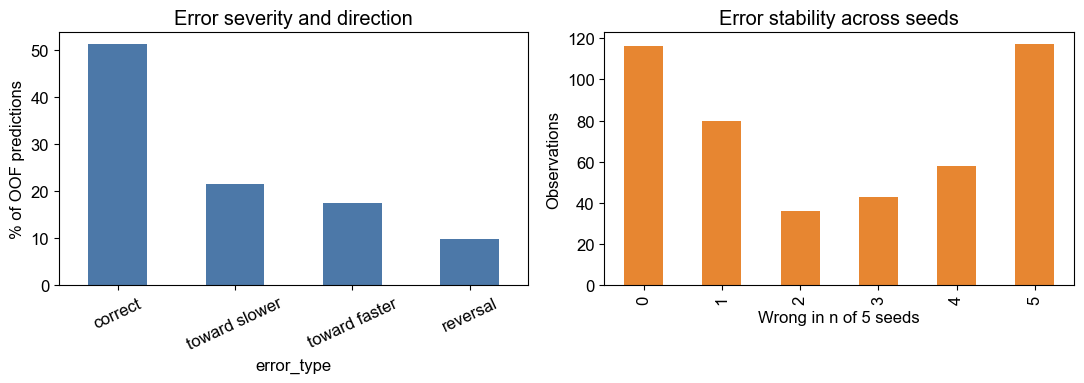

,amendment_cluster_chemical,n_predictions,n_observations,n_studies,accuracy,reversal_rate,mean_abs_error,dominant_error,error_rate,ci_low,ci_high
0,6,135,27,8,0.392593,0.125926,0.733333,no change → slower,0.607407,0.440952,0.731190
1,3,130,26,6,0.469231,0.053846,0.584615,no change → slower,0.530769,0.430309,0.750000
2,4,360,72,12,0.483333,0.127778,0.644444,faster → no change,0.516667,0.336212,0.662297
3,5,380,76,17,0.542105,0.173684,0.631579,slower → no change,0.457895,0.276535,0.632877
4,2,635,127,24,0.623622,0.045669,0.422047,faster → no change,0.376378,0.302658,0.467692
5,1,25,5,2,0.720000,0.000000,0.280000,faster → no change,0.280000,0.000000,0.700000


,pesticide_rdkit_cluster,n_predictions,n_observations,n_studies,accuracy,reversal_rate,mean_abs_error,dominant_error,error_rate,ci_low,ci_high
0,1,280,56,13,0.442857,0.117857,0.675000,slower → no change,0.557143,0.428571,0.714294
1,2,645,129,23,0.457364,0.133333,0.675969,faster → no change,0.542636,0.442462,0.637243
2,5,595,119,22,0.480672,0.117647,0.636975,faster → no change,0.519328,0.407764,0.644749
3,4,225,45,7,0.604444,0.022222,0.417778,faster → no change,0.395556,0.227969,0.769333
4,3,505,101,19,0.615842,0.057426,0.441584,faster → no change,0.384158,0.298809,0.484150


,soil_cluster,n_predictions,n_observations,n_studies,accuracy,reversal_rate,mean_abs_error,dominant_error,error_rate,ci_low,ci_high
0,1.0,815,163,27,0.504294,0.104294,0.600000,slower → no change,0.495706,0.396768,0.611718
1,2.0,875,175,36,0.518857,0.123429,0.604571,no change → slower,0.481143,0.391580,0.574170


In [4]:
# Error direction and severity
composition = (data.groupby(['observed', 'predicted']).size().rename('n').reset_index())
composition['percent'] = 100 * composition['n'] / composition['n'].sum()
display(composition)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
data['error_type'].value_counts(normalize=True).mul(100).plot.bar(ax=axes[0], color='#4c78a8')
axes[0].set(ylabel='% of OOF predictions', title='Error severity and direction'); axes[0].tick_params(axis='x', rotation=25)
row_errors['n_wrong'].value_counts().sort_index().plot.bar(ax=axes[1], color='#e78631')
axes[1].set(xlabel='Wrong in n of 5 seeds', ylabel='Observations', title='Error stability across seeds')
fig.tight_layout(); fig.savefig(OUT / 'error_composition_and_stability.png', dpi=220, bbox_inches='tight'); plt.show()

# Cluster-level 95% intervals by resampling whole studies
def study_bootstrap(column, repeats=500, seed=7):
    source = data.dropna(subset=[column]); studies = source['Study ID'].unique(); rng = np.random.default_rng(seed); rows = []
    for _ in range(repeats):
        chosen = rng.choice(studies, len(studies), replace=True)
        sample = pd.concat([source[source['Study ID'].eq(s)] for s in chosen], ignore_index=True)
        rows.append(sample.groupby(column)['correct'].mean().rsub(1))
    draws = pd.DataFrame(rows)
    return pd.DataFrame({'ci_low': draws.quantile(.025), 'ci_high': draws.quantile(.975)}).reset_index()

for name, column in [('amendment', OA), ('pesticide', PEST), ('soil', SOIL)]:
    ci = study_bootstrap(column)
    tables[name] = tables[name].merge(ci, on=column, how='left')
    tables[name].to_csv(OUT / f'{name}_error_summary_with_study_CI.csv', index=False)
    display(tables[name])


## Pairwise cluster maps

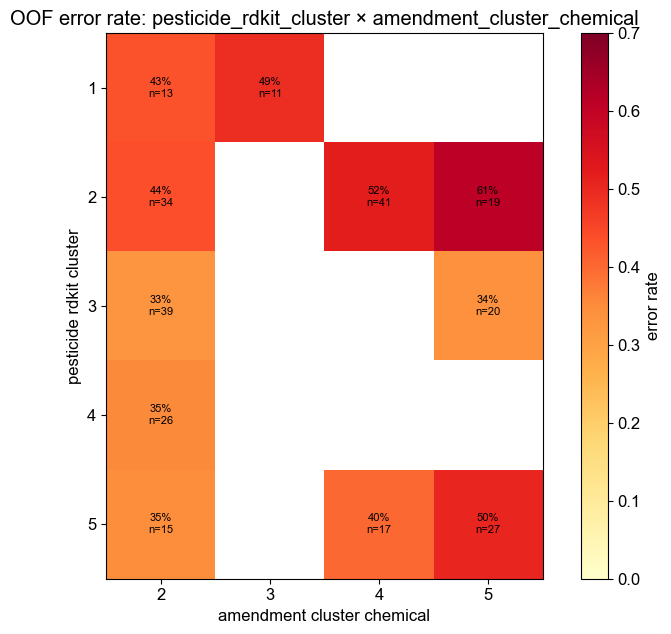

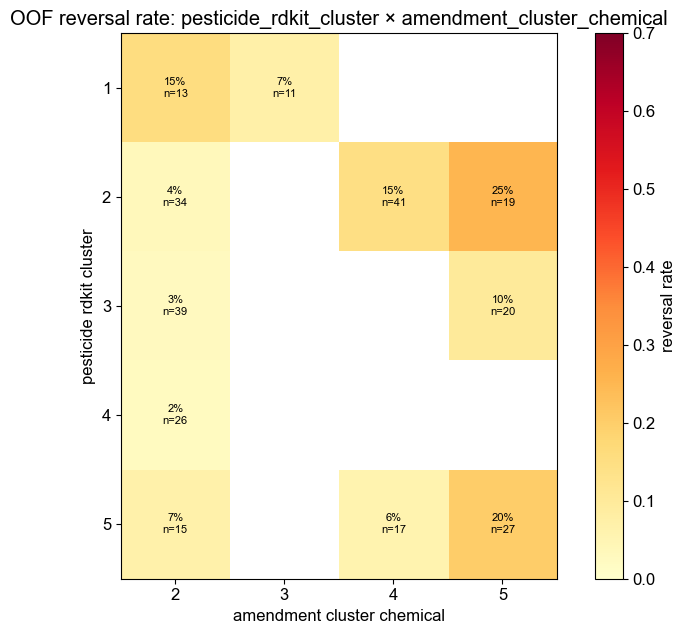

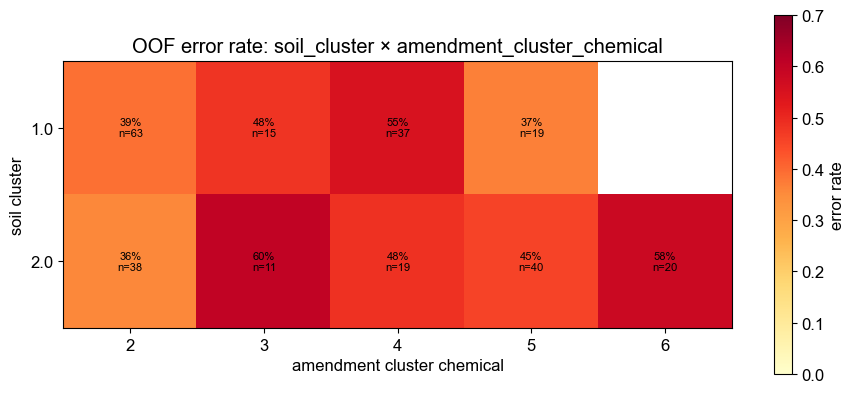

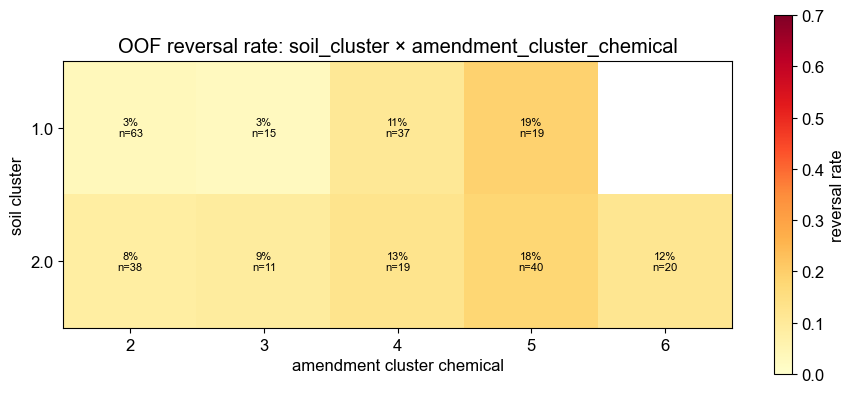

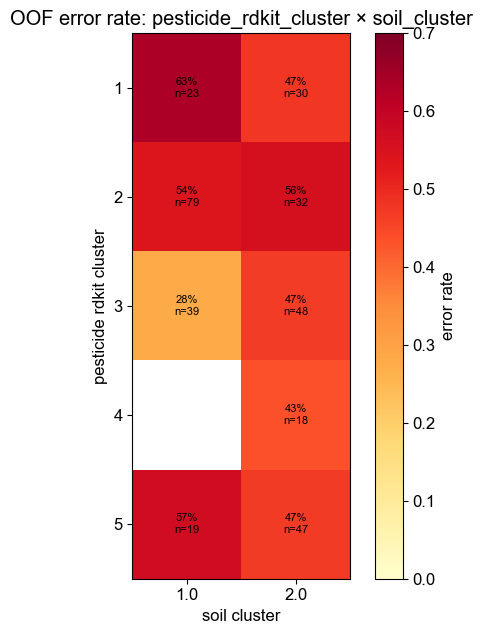

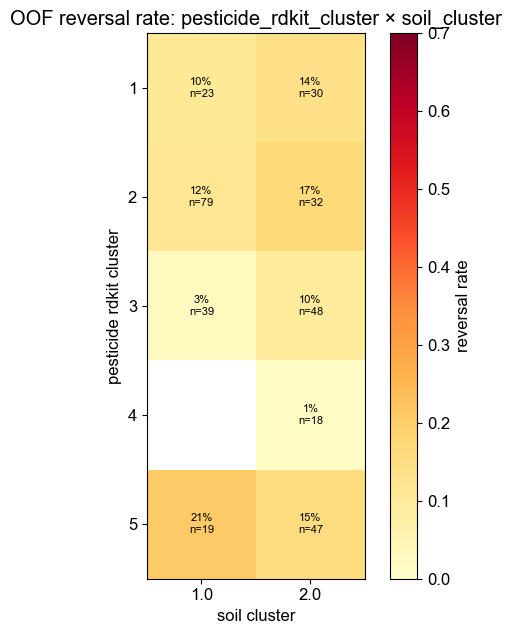

In [5]:
def cluster_heatmap(table, row, col, value, title, filename):
    shown = table.query('n_observations >= @MIN_N')
    rates = shown.pivot(index=row, columns=col, values=value).sort_index().sort_index(axis=1)
    counts = shown.pivot(index=row, columns=col, values='n_observations').reindex_like(rates)
    fig, ax = plt.subplots(figsize=(1.25 * len(rates.columns) + 3, .8 * len(rates) + 2.5))
    image = ax.imshow(rates, cmap='YlOrRd', vmin=0, vmax=max(.7, np.nanmax(rates)))
    for i in range(len(rates.index)):
        for j in range(len(rates.columns)):
            if pd.notna(rates.iloc[i, j]): ax.text(j, i, f'{rates.iloc[i,j]:.0%}\nn={counts.iloc[i,j]:.0f}', ha='center', va='center', fontsize=8)
    ax.set_xticks(range(len(rates.columns)), rates.columns); ax.set_yticks(range(len(rates.index)), rates.index)
    ax.set(xlabel=col.replace('_', ' '), ylabel=row.replace('_', ' '), title=title)
    fig.colorbar(image, ax=ax, label=value.replace('_', ' ')); fig.tight_layout()
    fig.savefig(OUT / filename, dpi=220, bbox_inches='tight'); plt.show()

pairs = [('pesticide_x_amendment', PEST, OA), ('soil_x_amendment', SOIL, OA), ('pesticide_x_soil', PEST, SOIL)]
for name, row, col in pairs:
    cluster_heatmap(tables[name], row, col, 'error_rate', f'OOF error rate: {row} × {col}', f'{name}_error_heatmap.png')
    cluster_heatmap(tables[name], row, col, 'reversal_rate', f'OOF reversal rate: {row} × {col}', f'{name}_reversal_heatmap.png')


## Amendment feedstock and processing

Error and reversal rates are evaluated separately for feedstock origin, processing type, and their combination. Counts and study-level bootstrap intervals are retained to avoid overinterpreting small groups.

,feedstock_group,n_predictions,n_observations,n_studies,accuracy,reversal_rate,mean_abs_error,dominant_error,error_rate,ci_low,ci_high
0,Sludge/biosolids,135,27,8,0.370370,0.177778,0.807407,slower → no change,0.629630,0.454750,0.786652
1,Lignocellulosic/woody plant biomass,860,172,33,0.483721,0.127907,0.644186,slower → no change,0.516279,0.426420,0.594291
2,Herbaceous/non-woody plant biomass,810,162,29,0.537037,0.079012,0.541975,faster → no change,0.462963,0.367912,0.588537
3,Animal-derived biomass,445,89,17,0.564045,0.056180,0.492135,faster → no change,0.435955,0.334070,0.626397


,processing_group,n_predictions,n_observations,n_studies,accuracy,reversal_rate,mean_abs_error,dominant_error,error_rate,ci_low,ci_high
0,Thermal,665,133,21,0.482707,0.111278,0.628571,faster → no change,0.517293,0.416243,0.639635
1,Unprocessed,705,141,33,0.510638,0.106383,0.595745,slower → no change,0.489362,0.377089,0.607722
2,Biological,880,176,33,0.535227,0.084091,0.548864,faster → no change,0.464773,0.399426,0.547169


,feedstock_group,processing_group,n_predictions,n_observations,n_studies,accuracy,reversal_rate,mean_abs_error,dominant_error,error_rate
10,Sludge/biosolids,Unprocessed,55,11,5,0.345455,0.072727,0.727273,no change → slower,0.654545
9,Sludge/biosolids,Biological,80,16,3,0.387500,0.250000,0.862500,faster → slower,0.612500
7,Lignocellulosic/woody plant biomass,Thermal,175,35,9,0.428571,0.194286,0.765714,slower → no change,0.571429
2,Animal-derived biomass,Unprocessed,185,37,10,0.437838,0.097297,0.659459,faster → no change,0.562162
8,Lignocellulosic/woody plant biomass,Unprocessed,250,50,13,0.484000,0.184000,0.700000,slower → no change,0.516000
3,Herbaceous/non-woody plant biomass,Biological,120,24,7,0.491667,0.141667,0.650000,no change → faster,0.508333
4,Herbaceous/non-woody plant biomass,Thermal,475,95,14,0.498947,0.084211,0.585263,faster → no change,0.501053
6,Lignocellulosic/woody plant biomass,Biological,435,87,20,0.505747,0.068966,0.563218,faster → no change,0.494253
5,Herbaceous/non-woody plant biomass,Unprocessed,215,43,10,0.646512,0.032558,0.386047,faster → no change,0.353488
0,Animal-derived biomass,Biological,245,49,8,0.657143,0.028571,0.371429,faster → no change,0.342857


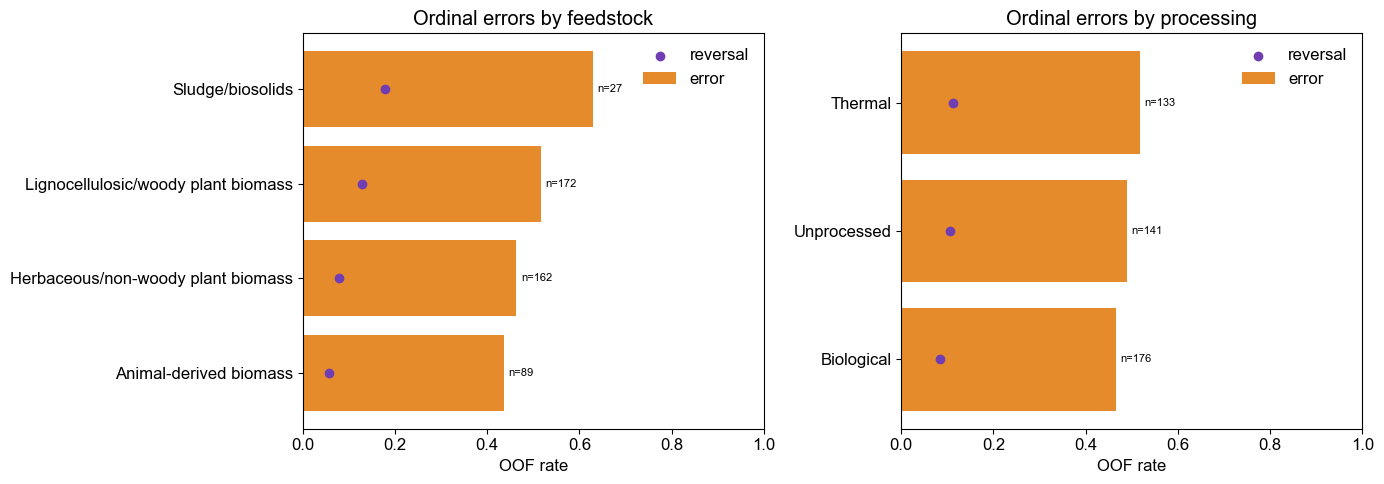

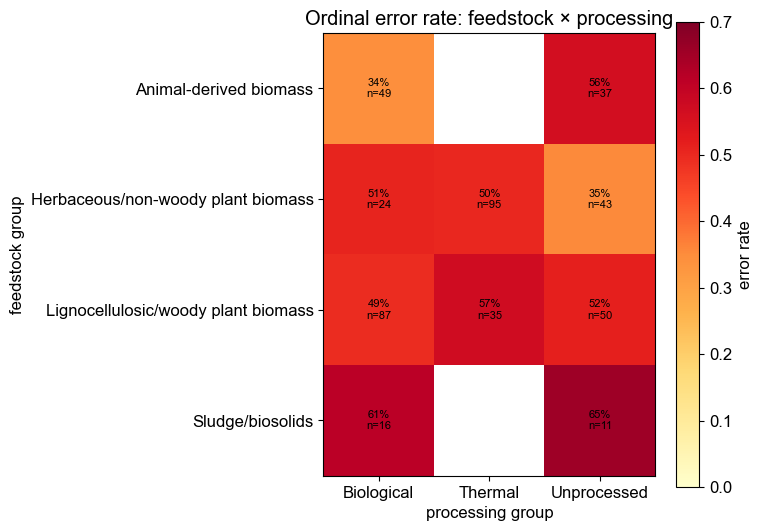

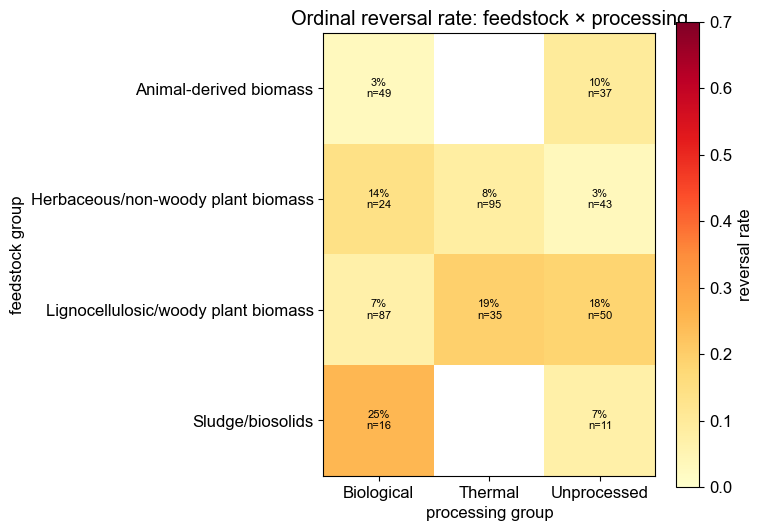

In [6]:
FEED, PROCESS = 'feedstock_group', 'processing_group'
feedstock = summarize([FEED]).merge(study_bootstrap(FEED), on=FEED, how='left')
processing = summarize([PROCESS]).merge(study_bootstrap(PROCESS), on=PROCESS, how='left')
feed_x_processing = summarize([FEED, PROCESS])
feedstock.to_csv(OUT / 'feedstock_error_summary_with_study_CI.csv', index=False)
processing.to_csv(OUT / 'processing_error_summary_with_study_CI.csv', index=False)
feed_x_processing.to_csv(OUT / 'feedstock_x_processing_error_summary.csv', index=False)
display(feedstock); display(processing); display(feed_x_processing.query('n_observations >= @MIN_N'))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, table, column, title in [(axes[0], feedstock, FEED, 'Ordinal errors by feedstock'),
                                  (axes[1], processing, PROCESS, 'Ordinal errors by processing')]:
    shown = table.sort_values('error_rate', ascending=True)
    ax.barh(shown[column].astype(str), shown['error_rate'], color='#e58b2b', label='error')
    ax.scatter(shown['reversal_rate'], shown[column].astype(str), color='#713db3', label='reversal', zorder=3)
    for y, (_, row) in enumerate(shown.iterrows()): ax.text(row.error_rate + .01, y, f'n={int(row.n_observations)}', va='center', fontsize=8)
    ax.set(xlim=(0, 1), xlabel='OOF rate', title=title); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(OUT / 'feedstock_processing_error_rates.png', dpi=220, bbox_inches='tight'); plt.show()
cluster_heatmap(feed_x_processing, FEED, PROCESS, 'error_rate', 'Ordinal error rate: feedstock × processing', 'feedstock_x_processing_error_heatmap.png')
cluster_heatmap(feed_x_processing, FEED, PROCESS, 'reversal_rate', 'Ordinal reversal rate: feedstock × processing', 'feedstock_x_processing_reversal_heatmap.png')


## Three-domain combinations and confident errors

In [7]:
three_way = tables['three_way'].query('n_observations >= @MIN_N').copy()
three_way['excess_error'] = three_way['error_rate'] - (1 - data['correct'].mean())
three_way.to_csv(OUT / 'three_way_supported_ranked.csv', index=False)
display(three_way.head(30))

high_margin_errors = (data.loc[(~data['correct']) & data['boundary_distance'].ge(HIGH_MARGIN)]
    .sort_values(['boundary_distance', 'directional_reversal'], ascending=False))
high_margin_errors.to_csv(OUT / 'high_margin_ordinal_errors.csv', index=False)
display(high_margin_errors[['analysis_row_id', 'Study ID', 'observed', 'predicted', 'score', 'cut1', 'cut2', 'boundary_distance', OA, PEST, SOIL]].head(30))

stable = row_errors.query('stable_error').sort_values(['n_reversals', 'n_wrong', 'mean_boundary_distance'], ascending=False)
stable.to_csv(OUT / 'stable_errors.csv', index=False)
display(stable.head(30))


,pesticide_rdkit_cluster,soil_cluster,amendment_cluster_chemical,n_predictions,n_observations,n_studies,accuracy,reversal_rate,mean_abs_error,dominant_error,error_rate,excess_error
12,2,1.0,5,50,10,5,0.360000,0.360000,1.000000,faster → slower,0.640000,0.152000
11,2,1.0,4,125,25,4,0.464000,0.056000,0.592000,faster → no change,0.536000,0.048000
40,5,2.0,5,55,11,7,0.509091,0.272727,0.763636,faster → slower,0.490909,0.002909
25,3,2.0,5,50,10,4,0.520000,0.200000,0.680000,faster → slower,0.480000,-0.008000
4,1,2.0,2,50,10,3,0.560000,0.200000,0.640000,no change → slower,0.440000,-0.048000
9,2,1.0,2,150,30,7,0.600000,0.040000,0.440000,no change → faster,0.400000,-0.088000
17,3,1.0,2,135,27,1,0.659259,0.037037,0.377778,no change → faster,0.340741,-0.147259
22,3,2.0,2,60,12,5,0.683333,0.000000,0.316667,no change → slower,0.316667,-0.171333
38,5,2.0,2,55,11,4,0.781818,0.090909,0.309091,no change → faster,0.218182,-0.269818


,analysis_row_id,Study ID,observed,predicted,score,cut1,cut2,boundary_distance,amendment_cluster_chemical,pesticide_rdkit_cluster,soil_cluster
718,316,S140,faster,slower,2.133790,0.715561,1.203883,0.929908,5,2,2.0
268,316,S140,faster,slower,2.017455,0.677221,1.160973,0.856482,5,2,2.0
412,468,S087,faster,slower,1.878526,0.677221,1.160973,0.717553,6,5,2.0
421,477,S087,no change,slower,1.878526,0.677221,1.160973,0.717553,6,5,2.0
427,483,S087,no change,slower,1.873089,0.677221,1.160973,0.712116,6,1,2.0
414,470,S087,faster,slower,1.864115,0.677221,1.160973,0.703141,NaN,5,2.0
423,479,S087,no change,slower,1.864115,0.677221,1.160973,0.703141,NaN,5,2.0
1764,470,S087,faster,slower,1.884928,0.688959,1.195421,0.689508,NaN,5,2.0
1773,479,S087,no change,slower,1.884928,0.688959,1.195421,0.689508,NaN,5,2.0
862,468,S087,faster,slower,1.888087,0.715561,1.203883,0.684205,6,5,2.0


,analysis_row_id,Study ID,observed,n_wrong,n_reversals,prediction_agreement,consensus_prediction,mean_score,score_sd,mean_boundary_distance,...,processing_group,soil_silt,soil_pH,soil_OC,amendment_pH,amendment_carbon,amendment_application_rate_g_kg,log1p_pesticide_concentration,ln_DT50_ratio,stable_error
414,470,S087,faster,5,5,1.0,slower,1.895320,0.025768,0.677697,...,Biological,8.20,7.90,4700.000000,7.10,267000.000000,50.0,1.098612,-0.477259,True
412,468,S087,faster,5,5,1.0,slower,1.881462,0.017027,0.663839,...,Biological,8.20,7.90,4700.000000,6.10,248000.000000,50.0,1.098612,-0.623351,True
268,316,S140,faster,5,5,1.0,slower,1.706501,0.396779,0.558086,...,Biological,8.37,8.40,3654.292343,5.80,551044.083527,100.0,1.386294,-0.233423,True
424,480,S087,faster,5,5,1.0,slower,1.764425,0.044643,0.546802,...,Biological,8.20,7.90,4700.000000,6.10,248000.000000,50.0,1.098612,-0.366625,True
413,469,S087,faster,5,5,1.0,slower,1.741838,0.114928,0.524216,...,Unprocessed,8.20,7.90,4700.000000,5.00,418000.000000,50.0,1.098612,-1.566209,True
422,478,S087,faster,5,5,1.0,slower,1.741838,0.114928,0.524216,...,Unprocessed,8.20,7.90,4700.000000,5.00,418000.000000,50.0,1.098612,-0.629198,True
428,484,S087,faster,5,5,1.0,slower,1.708914,0.094094,0.491292,...,Unprocessed,8.20,7.90,4700.000000,5.00,418000.000000,50.0,1.098612,-0.485063,True
416,472,S087,faster,5,5,1.0,slower,1.625998,0.093242,0.408376,...,Unprocessed,8.20,7.90,4700.000000,5.00,418000.000000,50.0,1.098612,-0.537583,True
425,481,S087,faster,5,5,1.0,slower,1.625998,0.093242,0.408376,...,Unprocessed,8.20,7.90,4700.000000,5.00,418000.000000,50.0,1.098612,-0.797408,True
284,334,S129,slower,5,5,1.0,faster,0.322008,0.105318,0.360006,...,Unprocessed,52.00,5.80,15661.252900,NaN,NaN,50.0,5.198497,0.578484,True


## Continuous-property profiles of correct, adjacent-error, and reversal observations

,property,consensus_error_type,count,median,mean,std
0,amendment_application_rate_g_kg,adjacent error,162,40.000000,60.199588,89.858893
1,amendment_application_rate_g_kg,correct,216,50.000000,68.316512,86.806672
2,amendment_application_rate_g_kg,reversal,41,50.000000,51.463415,53.505186
3,amendment_carbon,adjacent error,131,336000.000000,348522.263919,176899.570273
4,amendment_carbon,correct,199,383000.000000,395982.153348,189307.903568
5,amendment_carbon,reversal,34,418000.000000,464291.251535,153809.378610
6,amendment_pH,adjacent error,118,7.500000,7.725932,1.557101
7,amendment_pH,correct,175,7.500000,7.557200,1.523332
8,amendment_pH,reversal,33,6.400000,7.281818,1.925241
9,ln_DT50_ratio,adjacent error,174,-0.040384,-0.048950,0.965888


/var/folders/ff/4s2lwblx3vnbvdnzx0n9907c0000gn/T/ipykernel_52610/100767974.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(parts, labels=['correct', 'adjacent', 'reversal'], showfliers=False)
/var/folders/ff/4s2lwblx3vnbvdnzx0n9907c0000gn/T/ipykernel_52610/100767974.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(parts, labels=['correct', 'adjacent', 'reversal'], showfliers=False)
/var/folders/ff/4s2lwblx3vnbvdnzx0n9907c0000gn/T/ipykernel_52610/100767974.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(parts, labels=['correct', 'adjacent', 'reversal'], showfliers=False)
/

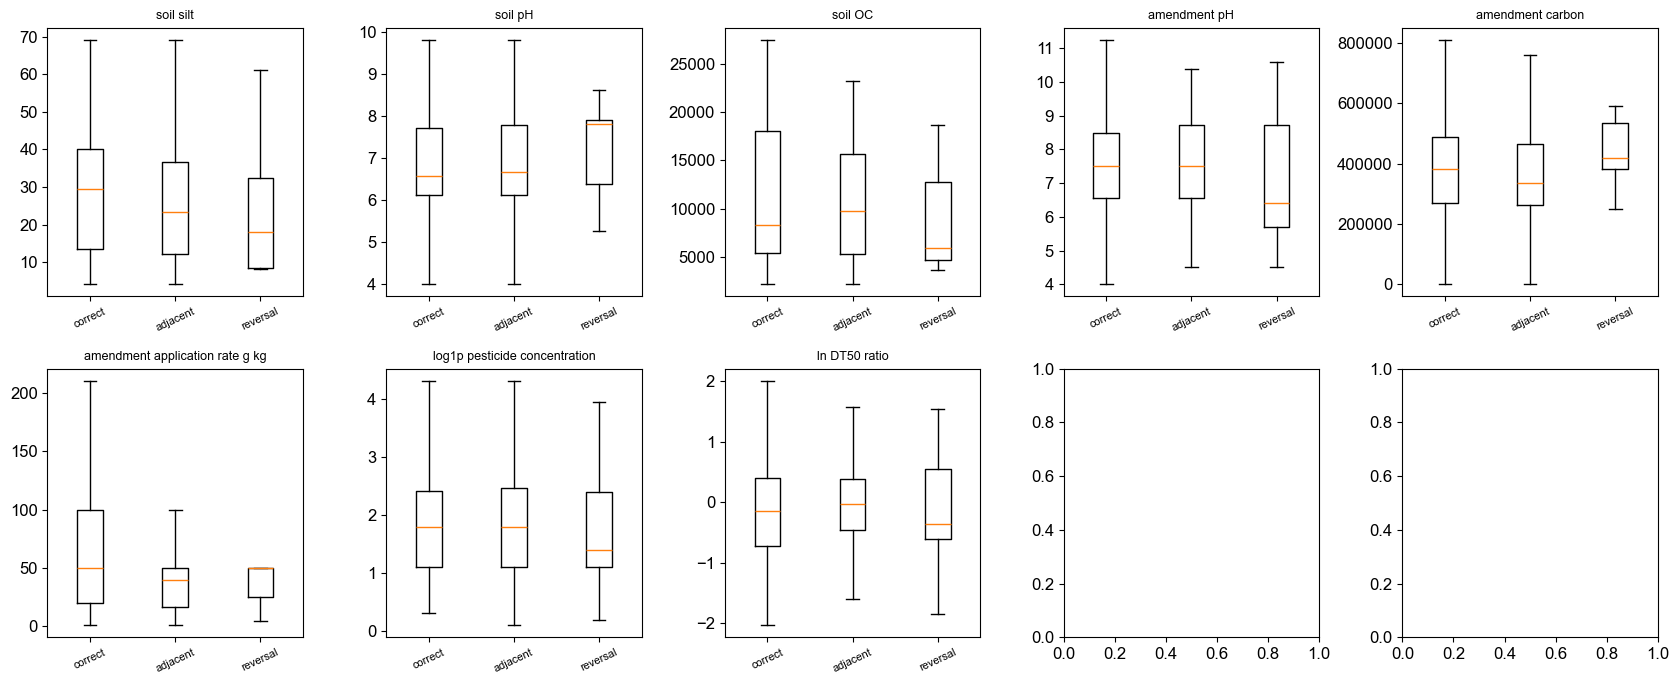

In [8]:
row_errors['consensus_step'] = row_errors['consensus_prediction'].map(order) - row_errors['observed'].map(order)
row_errors['consensus_error_type'] = np.select(
    [row_errors['consensus_step'].eq(0), row_errors['consensus_step'].abs().eq(2)],
    ['correct', 'reversal'], default='adjacent error')
profile = (row_errors.melt(id_vars=['analysis_row_id', 'consensus_error_type'], value_vars=CONTINUOUS,
                           var_name='property', value_name='value')
    .groupby(['property', 'consensus_error_type'])['value'].agg(['count', 'median', 'mean', 'std']).reset_index())
profile.to_csv(OUT / 'continuous_error_profiles.csv', index=False)
display(profile)

fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for ax, feature in zip(axes.flat, CONTINUOUS):
    parts = [row_errors.loc[row_errors['consensus_error_type'].eq(k), feature].dropna() for k in ['correct', 'adjacent error', 'reversal']]
    ax.boxplot(parts, labels=['correct', 'adjacent', 'reversal'], showfliers=False)
    ax.set_title(feature.replace('_', ' '), fontsize=9); ax.tick_params(axis='x', rotation=25, labelsize=8)
fig.tight_layout(); fig.savefig(OUT / 'continuous_properties_by_error_type.png', dpi=220, bbox_inches='tight'); plt.show()


## Saved ordinal performance

In [9]:
metrics_ordinal = pd.read_csv(RUN / 'metrics_ordinal.csv')
display(metrics_ordinal)
display(metrics_ordinal.drop(columns=['variant', 'seed']).agg(['mean', 'std']).round(4))


,variant,seed,bal_acc,accuracy,macro_f1,recall_faster,recall_no_change,recall_slower,reversal_rate,n_reversals,mae_steps,qwk,spearman_score
0,ordinal,0,0.450507,0.466667,0.454013,0.505051,0.339623,0.506849,0.111111,50,0.644444,0.382903,0.400745
1,ordinal,1,0.504324,0.520000,0.505299,0.585859,0.433962,0.493151,0.095556,43,0.575556,0.448463,0.466960
2,ordinal,2,0.491011,0.497778,0.489697,0.520202,0.452830,0.500000,0.097778,44,0.600000,0.422291,0.452282
3,ordinal,3,0.542259,0.537778,0.534594,0.500000,0.537736,0.589041,0.093333,42,0.555556,0.459679,0.457630
4,ordinal,4,0.521651,0.537778,0.521942,0.601010,0.443396,0.520548,0.097778,44,0.560000,0.462275,0.446128


,bal_acc,accuracy,macro_f1,recall_faster,recall_no_change,recall_slower,reversal_rate,n_reversals,mae_steps,qwk,spearman_score
mean,0.5020,0.5120,0.5011,0.5424,0.4415,0.5219,0.0991,44.6000,0.5871,0.4351,0.4447
std,0.0346,0.0302,0.0313,0.0475,0.0704,0.0389,0.0070,3.1305,0.0365,0.0332,0.0258


## Three-way prediction applicability matrix

Exact accuracy and complete directional-reversal rates for pesticide × soil × amendment combinations with at least 10 unique observations from at least 3 independent studies. Blank cells are deliberately suppressed because their support is inadequate.

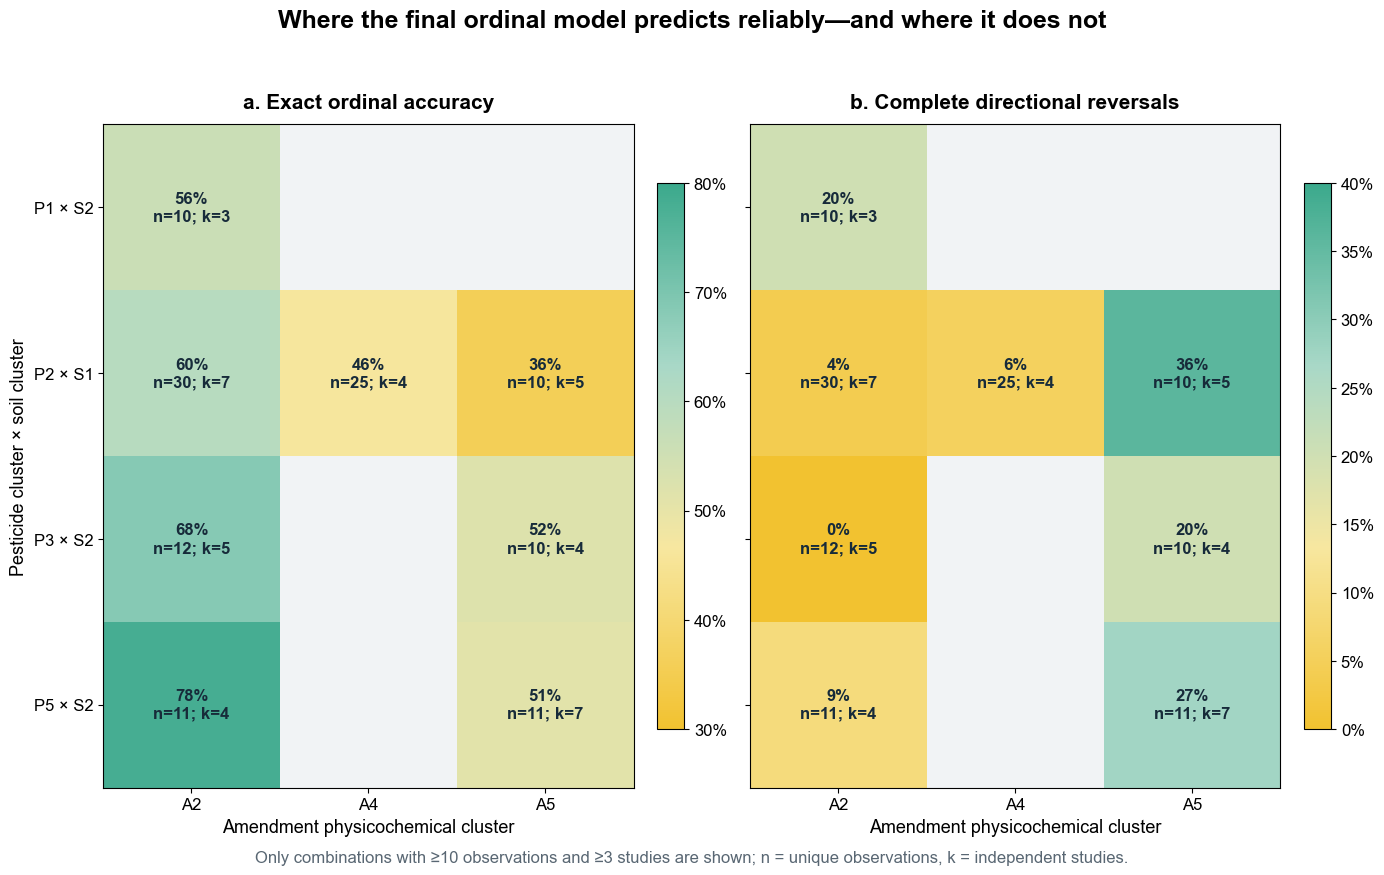

,combination,exact_accuracy_pct,reversal_rate_pct,n_observations,n_studies,dominant_error
38,P5 × S2 × A2,78.2,9.1,11,4,no change → faster
22,P3 × S2 × A2,68.3,0.0,12,5,no change → slower
9,P2 × S1 × A2,60.0,4.0,30,7,no change → faster
4,P1 × S2 × A2,56.0,20.0,10,3,no change → slower
25,P3 × S2 × A5,52.0,20.0,10,4,faster → slower
40,P5 × S2 × A5,50.9,27.3,11,7,faster → slower
11,P2 × S1 × A4,46.4,5.6,25,4,faster → no change
12,P2 × S1 × A5,36.0,36.0,10,5,faster → slower


In [10]:
# Direct visual evidence for the best- and worst-predicted three-way contexts
MIN_STUDIES_MATRIX = 3
supported = tables['three_way'].query(
    'n_observations >= @MIN_N and n_studies >= @MIN_STUDIES_MATRIX'
).copy()
supported['context'] = (
    'P' + supported[PEST].astype(int).astype(str)
    + ' × S' + supported[SOIL].astype(int).astype(str)
)
supported['amendment'] = 'A' + supported[OA].astype(int).astype(str)

row_order = sorted(supported['context'].unique(), key=lambda x: (int(x.split(' × ')[0][1:]), int(x.split('S')[1])))
col_order = sorted(supported['amendment'].unique(), key=lambda x: int(x[1:]))

def matrix(column):
    return (supported.pivot(index='context', columns='amendment', values=column)
            .reindex(index=row_order, columns=col_order))

accuracy = matrix('accuracy')
reversal = matrix('reversal_rate')
n_obs = matrix('n_observations')
n_studies = matrix('n_studies')

yellow_green = LinearSegmentedColormap.from_list(
    'yellow_green', ['#F2C230', '#F7E7A0', '#A8D8C7', '#3BA98C'])
fig, axes = plt.subplots(1, 2, figsize=(14, 1.15 * len(row_order) + 3.6), sharey=True)
panels = [
    (axes[0], accuracy, yellow_green, .30, .80, 'a. Exact ordinal accuracy'),
    (axes[1], reversal, yellow_green, 0, .40, 'b. Complete directional reversals'),
]
for ax, values, colourmap, lower, upper, title in panels:
    cmap = colourmap.copy(); cmap.set_bad('#f1f3f5')
    image = ax.imshow(values, cmap=cmap, vmin=lower, vmax=upper, aspect='auto')
    ax.set_xticks(range(len(col_order)), col_order, fontsize=12)
    ax.set_yticks(range(len(row_order)), row_order, fontsize=12)
    ax.set_xlabel('Amendment physicochemical cluster', fontsize=13)
    ax.set_title(title, fontsize=15, weight='bold', pad=12)
    for i in range(len(row_order)):
        for j in range(len(col_order)):
            value = values.iat[i, j]
            if pd.isna(value):
                continue
            support = f'n={int(n_obs.iat[i, j])}; k={int(n_studies.iat[i, j])}'
            ax.text(j, i, f'{value:.0%}\n{support}', ha='center', va='center',
                    fontsize=12, weight='bold', color='#172b3a')
    cbar = fig.colorbar(image, ax=ax, fraction=.047, pad=.04, format=lambda x, pos: f'{x:.0%}')
    cbar.ax.tick_params(labelsize=12)

axes[0].set_ylabel('Pesticide cluster × soil cluster', fontsize=13)
fig.suptitle('Where the final ordinal model predicts reliably—and where it does not',
             fontsize=18, weight='bold', y=1.03)
fig.text(.5, -.01,
         f'Only combinations with ≥{MIN_N} observations and ≥{MIN_STUDIES_MATRIX} studies are shown; '
         'n = unique observations, k = independent studies.',
         ha='center', fontsize=12, color='#596773')
fig.tight_layout()
fig.savefig(OUT / 'three_way_accuracy_reversal_matrix.png', dpi=250, bbox_inches='tight')
fig.savefig(OUT / 'three_way_accuracy_reversal_matrix.pdf', bbox_inches='tight')
plt.show()

ranked_contexts = (supported.assign(
    combination=supported['context'] + ' × ' + supported['amendment'],
    exact_accuracy_pct=100 * supported['accuracy'],
    reversal_rate_pct=100 * supported['reversal_rate'])
    [['combination', 'exact_accuracy_pct', 'reversal_rate_pct',
      'n_observations', 'n_studies', 'dominant_error']]
    .sort_values(['exact_accuracy_pct', 'n_studies'], ascending=[False, False]))
ranked_contexts.to_csv(OUT / 'three_way_supported_accuracy_ranking.csv', index=False)
display(ranked_contexts.round({'exact_accuracy_pct': 1, 'reversal_rate_pct': 1}))


## Full three-way combination coverage

Coverage of all pesticide × soil × amendment cluster combinations. Cell colour represents the number of unique observations; annotations give observations (`n`) and independent studies (`k`). Thick borders identify combinations retained in the accuracy/reversal matrix.

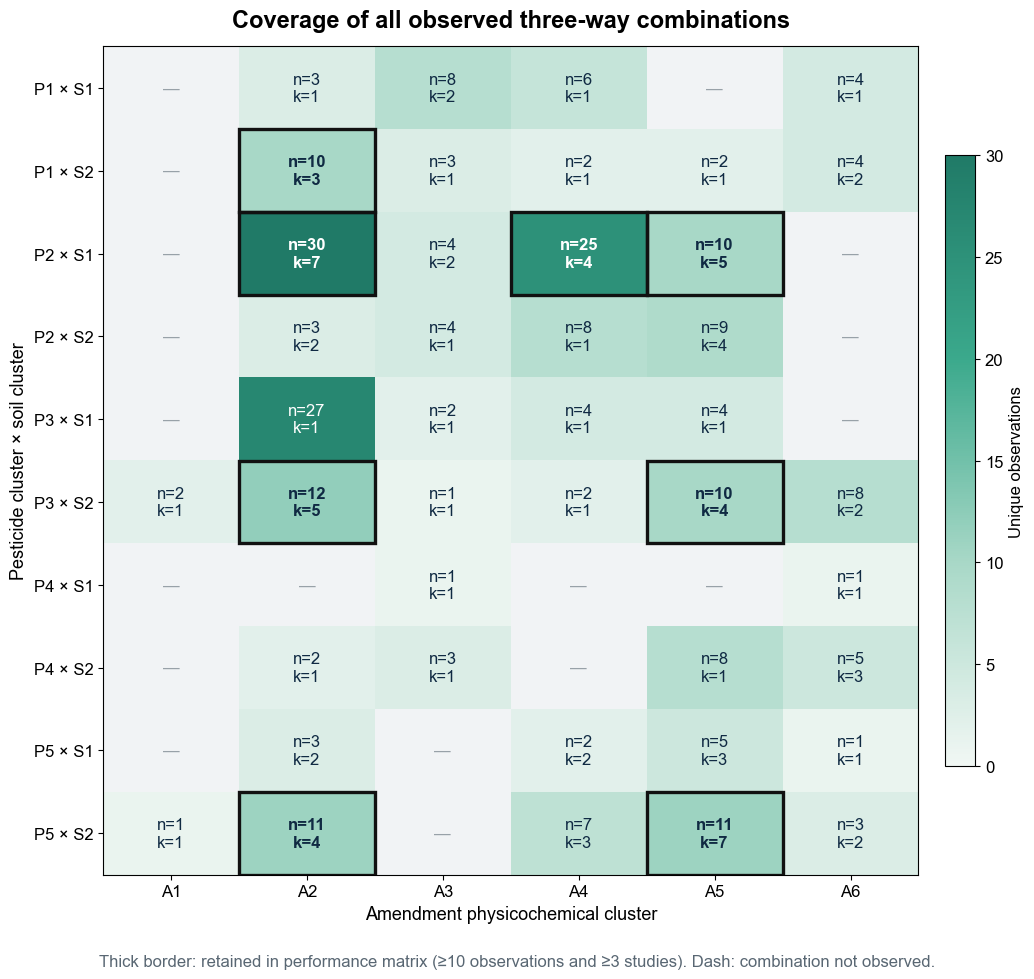

In [11]:
# Full data-coverage map, including combinations too sparse for performance claims
all_three = tables['three_way'].copy()
all_three['context'] = (
    'P' + all_three[PEST].astype(int).astype(str)
    + ' × S' + all_three[SOIL].astype(int).astype(str)
)
all_three['amendment'] = 'A' + all_three[OA].astype(int).astype(str)

full_rows = [f'P{p} × S{s}' for p in range(1, 6) for s in range(1, 3)]
full_cols = [f'A{a}' for a in range(1, 7)]

def full_matrix(column):
    return (all_three.pivot(index='context', columns='amendment', values=column)
            .reindex(index=full_rows, columns=full_cols))

coverage_n = full_matrix('n_observations')
coverage_k = full_matrix('n_studies')

cmap = LinearSegmentedColormap.from_list(
    'coverage_green', ['#F1F7F4', '#A8D8C7', '#3BA98C', '#207A67'])
cmap.set_bad('#f1f3f5')
fig, ax = plt.subplots(figsize=(10.5, 10))
image = ax.imshow(coverage_n, cmap=cmap, vmin=0, vmax=np.nanmax(coverage_n), aspect='auto')
ax.set_xticks(range(len(full_cols)), full_cols, fontsize=12)
ax.set_yticks(range(len(full_rows)), full_rows, fontsize=12)
ax.set_xlabel('Amendment physicochemical cluster', fontsize=13)
ax.set_ylabel('Pesticide cluster × soil cluster', fontsize=13)
ax.set_title('Coverage of all observed three-way combinations', fontsize=17, weight='bold', pad=14)

for i in range(len(full_rows)):
    for j in range(len(full_cols)):
        n = coverage_n.iat[i, j]
        if pd.isna(n):
            ax.text(j, i, '—', ha='center', va='center', color='#98a1a8', fontsize=12)
            continue
        k = int(coverage_k.iat[i, j])
        adequate = n >= MIN_N and k >= MIN_STUDIES_MATRIX
        text_colour = 'white' if n >= .65 * np.nanmax(coverage_n) else '#102a43'
        ax.text(j, i, f'n={int(n)}\nk={k}', ha='center', va='center', fontsize=12,
                weight='bold' if adequate else 'normal', color=text_colour)
        if adequate:
            ax.add_patch(plt.Rectangle((j-.5, i-.5), 1, 1, fill=False,
                                       edgecolor='#111111', linewidth=2.4))

cbar = fig.colorbar(image, ax=ax, fraction=.035, pad=.03)
cbar.set_label('Unique observations', fontsize=12)
cbar.ax.tick_params(labelsize=12)
fig.text(.5, .025,
         f'Thick border: retained in performance matrix (≥{MIN_N} observations and ≥{MIN_STUDIES_MATRIX} studies). '
         'Dash: combination not observed.',
         ha='center', fontsize=12, color='#596773')
fig.tight_layout(rect=(0, .05, 1, 1))
fig.savefig(OUT / 'three_way_full_coverage_matrix.png', dpi=250, bbox_inches='tight')
fig.savefig(OUT / 'three_way_full_coverage_matrix.pdf', bbox_inches='tight')
plt.show()

all_three.assign(
    combination=all_three['context'] + ' × ' + all_three['amendment'],
    adequately_supported=(all_three['n_observations'].ge(MIN_N)
                          & all_three['n_studies'].ge(MIN_STUDIES_MATRIX))
).to_csv(OUT / 'three_way_full_combination_inventory.csv', index=False)


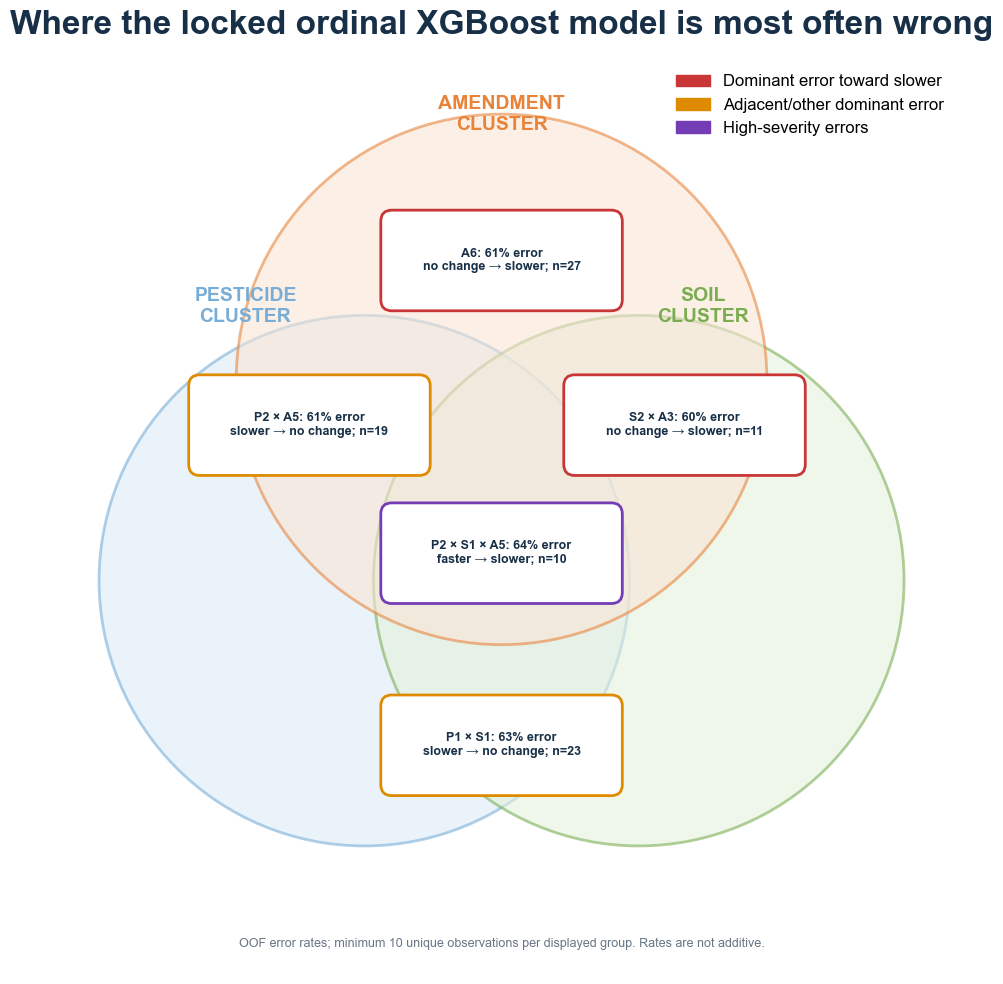

In [12]:
# Conceptual summary: highest-error adequately supported groups/combinations
def worst(name, n=1):
    x = tables[name].query('n_observations >= @MIN_N')
    return x.head(n)

def label(row, cols):
    ids = ' × '.join(f'{c[0].upper()}{int(row[c])}' for c in cols)
    return f'{ids}: {row.error_rate:.0%} error\n{row.dominant_error}; n={int(row.n_observations)}'

items = []
specs = [
    ('amendment', [OA], (0.50, 0.78)),
    ('pesticide_x_amendment', [PEST, OA], (0.29, 0.60)),
    ('soil_x_amendment', [SOIL, OA], (0.70, 0.60)),
    ('pesticide_x_soil', [PEST, SOIL], (0.50, 0.25)),
    ('three_way', [PEST, SOIL, OA], (0.50, 0.46)),
]
for name, cols, xy in specs:
    x = worst(name)
    if len(x): items.append((label(x.iloc[0], cols), xy, x.iloc[0]))

fig, ax = plt.subplots(figsize=(10, 10))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal', adjustable='box'); ax.axis('off')
circles = [
    ((0.35, 0.43), 0.29, '#dcebf7', '#77add7', 'PESTICIDE\nCLUSTER', (0.22, 0.73)),
    ((0.65, 0.43), 0.29, '#e4f0dc', '#79ad50', 'SOIL\nCLUSTER', (0.72, 0.73)),
    ((0.50, 0.65), 0.29, '#f9e4d4', '#e88339', 'AMENDMENT\nCLUSTER', (0.50, 0.94)),
]
for centre, radius, face, edge, text, text_xy in circles:
    ax.add_patch(Circle(centre, radius, facecolor=face, edgecolor=edge, lw=2, alpha=.58))
    ax.text(*text_xy, text, ha='center', va='center', color=edge, weight='bold', fontsize=14)

colours = {'reversal': '#743db6', 'slower': '#c93636', 'other': '#df8b00'}
for text, (x, y), row in items:
    transition = str(row.dominant_error)
    kind = 'reversal' if transition in ['faster → slower', 'slower → faster'] else ('slower' if '→ slower' in transition else 'other')
    color = colours[kind]
    ax.add_patch(FancyBboxPatch((x-.12, y-.043), .24, .086, boxstyle='round,pad=.012', facecolor='white', edgecolor=color, lw=2))
    ax.text(x, y, text, ha='center', va='center', fontsize=9, weight='bold', color='#183047')

ax.set_title('Where the locked ordinal XGBoost model is most often wrong', fontsize=24, weight='bold', color='#183047', pad=18)
ax.legend(handles=[Patch(color=colours['slower'], label='Dominant error toward slower'),
                   Patch(color=colours['other'], label='Adjacent/other dominant error'),
                   Patch(color=colours['reversal'], label='High-severity errors')],
          frameon=False, loc='upper right')
ax.text(.5, .03, f'OOF error rates; minimum {MIN_N} unique observations per displayed group. Rates are not additive.', ha='center', color='#687684', fontsize=9)
fig.tight_layout()
fig.savefig(OUT / 'conceptual_cluster_error_map.png', dpi=250, bbox_inches='tight')
plt.show()
